# 01. Pobranie i sprawdzenie danych

Notebook pobiera dzienne świece par `BNBUSDT` i `BTCUSDT` z publicznego API Binance i sprawdza ich jakość zgodnie z rozdziałami 7 i 10 dokumentu [`wymagania-i-zakres.md`](../../requirements/wymagania-i-zakres.md).

- Pobierane są tylko zamknięte świece, więc dane kończą się na dniu poprzednim.
- Okres analizy zaczyna się 1 stycznia 2023 roku. Dodatkowo pobieranych jest 200 dni wcześniejszych, potrzebnych do wskaźników kroczących i okien estymacji w analizie wydarzeń.
- Błędne rekordy są odrzucane: brakujące lub nieskończone liczby, świeca, która nie zaczyna się o 00:00 UTC albo nie trwa doby, niespójne ceny i ujemny wolumen.
- Brakujące dni są tylko odnotowywane i liczone dla całego żądanego okresu, więc widać też braki na jego początku i końcu. Dzienne zmiany ceny powyżej 50% są oznaczane do ręcznej weryfikacji.
- Dane nie są zapisywane do repozytorium. Kod pobierania i walidacji znajduje się w module [`binance_data.py`](binance_data.py).

In [1]:
from datetime import date, timedelta

import matplotlib.pyplot as plt
import pandas as pd

import binance_data as bd

PERIOD_START = date(2023, 1, 1)
WARMUP_DAYS = 200
SYMBOLS = ["BNBUSDT", "BTCUSDT"]

## 1. Pobranie danych

In [2]:
fetch_start = PERIOD_START - timedelta(days=WARMUP_DAYS)
raw = {symbol: bd.fetch_daily_klines(symbol, fetch_start) for symbol in SYMBOLS}

for symbol, frame in raw.items():
    if frame.empty:
        print(f"{symbol}: brak świec.")
    else:
        print(f"{symbol}: {len(frame)} świec, od {frame.index.min().date()} do {frame.index.max().date()}")

BNBUSDT: 1620 świec, od 2022-06-15 do 2026-11-20
BTCUSDT: 1620 świec, od 2022-06-15 do 2026-11-20


## 2. Walidacja

In [3]:
clean, reports = {}, {}
for symbol, frame in raw.items():
    clean[symbol], reports[symbol] = bd.validate(frame)

pd.DataFrame({
    symbol: {
        "liczba świec": r["rows"],
        "oczekiwane dni": r["expected_days"],
        "poprawne dni": r["valid_days"],
        "daty w kolejności rosnącej": r["sorted_by_date"],
        "powtórzone daty": len(r["duplicated_dates"]),
        "odrzucone rekordy": len(r["invalid_records"]),
        "brakujące dni": len(r["missing_days"]),
        "zmiany ceny powyżej 50%": len(r["big_moves"]),
        "pierwszy dzień": r["first_day"],
        "ostatni dzień": r["last_day"],
    }
    for symbol, r in reports.items()
})

,BNBUSDT,BTCUSDT
liczba świec,1620,1620
oczekiwane dni,1620,1620
poprawne dni,1620,1620
daty w kolejności rosnącej,True,True
powtórzone daty,0,0
odrzucone rekordy,0,0
brakujące dni,0,0
zmiany ceny powyżej 50%,0,0
pierwszy dzień,2022-06-15,2022-06-15
ostatni dzień,2026-11-20,2026-11-20


In [4]:
for symbol, r in reports.items():
    details = {
        "powtórzone daty": r["duplicated_dates"],
        "odrzucone rekordy": r["invalid_records"],
        "brakujące dni": r["missing_days"],
        "zmiany ceny powyżej 50%": r["big_moves"],
    }
    problems = {name: value for name, value in details.items() if value}
    if problems:
        print(symbol, problems)
    else:
        print(f"{symbol}: brak problemów z danymi.")

BNBUSDT: brak problemów z danymi.
BTCUSDT: brak problemów z danymi.


## 3. Okres analizy

In [5]:
for symbol, frame in clean.items():
    period = frame.loc[pd.Timestamp(PERIOD_START):]
    if period.empty:
        print(f"{symbol}: brak poprawnych cen w okresie analizy, {len(frame)} cen wcześniejszych")
        continue
    print(
        f"{symbol}: okres analizy od {period.index.min().date()} do {period.index.max().date()}, "
        f"{len(period)} cen, do tego {len(frame) - len(period)} cen wcześniejszych"
    )

BNBUSDT: okres analizy od 2023-01-01 do 2026-11-20, 1420 cen, do tego 200 cen wcześniejszych
BTCUSDT: okres analizy od 2023-01-01 do 2026-11-20, 1420 cen, do tego 200 cen wcześniejszych


In [6]:
clean["BNBUSDT"].tail()

,open,high,low,close,volume,quote_volume,trades,open_time,close_time
date,,,,,,,,,
2026-11-16,596.79,597.91,583.81,591.23,110619.436,6.535831e+07,549584.0,1.794787e+12,1.794874e+12
2026-11-17,591.24,599.42,580.78,597.47,132049.413,7.807172e+07,541902.0,1.794874e+12,1.794960e+12
2026-11-18,597.46,598.00,575.37,582.71,117979.237,6.929849e+07,558389.0,1.794960e+12,1.795046e+12
2026-11-19,582.71,594.00,575.71,580.25,101129.521,5.932136e+07,523088.0,1.795046e+12,1.795133e+12
2026-11-20,580.24,582.71,530.00,540.84,242463.968,1.342332e+08,903954.0,1.795133e+12,1.795219e+12


## 4. Ceny zamknięcia

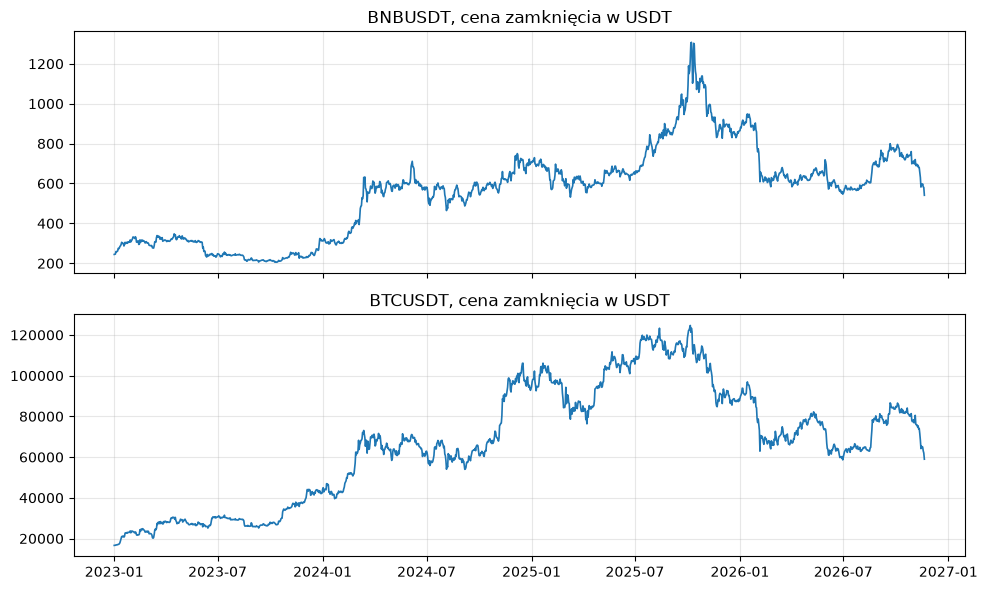

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for ax, symbol in zip(axes, SYMBOLS):
    series = clean[symbol].loc[pd.Timestamp(PERIOD_START):, "close"]
    ax.plot(series.index, series.values, linewidth=1.2)
    ax.set_title(f"{symbol}, cena zamknięcia w USDT")
    ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

In [8]:
last_days = [r["last_day"] for r in reports.values()]
if any(day is None for day in last_days):
    print("Brak poprawnych danych do analizy.")
else:
    print(f"Dane do dnia {min(last_days)} (UTC).")

Dane do dnia 2026-11-20 (UTC).
